# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 20: Paper Figures Generator

### Objective

This last notebook turns the results of the whole project into **publication-quality figures**, with captions and LaTeX snippets:

| Figure | Content |
|---|---|
| **Pipeline diagram** | The whole method on one page |
| **Dataset statistics** | Identities, images per identity, image quality, accepted synthetic images |
| **Sample synthetic images** | Real strips next to generated strips of the same identity |
| **Embedding visualizations** | t-SNE / UMAP of real, held-out, synthetic, and unseen-person images |
| **ROC / DET curves** | Within-dataset and cross-dataset, all models |
| **Ablation charts** | Change in EER for every ablation arm, and the trend with the number of synthetic images |
| **Cross-dataset comparison** | Domain gap, EER and Rank-1 by shot, threshold transfer |
| **Qualitative failure cases** | Wrong matches, weak matches, rejected synthetic images, and image quality of failures |

### Important boundary of this notebook

This notebook **reads results and draws them**. It trains and tunes nothing. Only the recognition failure cases re-load the best model of Notebook 13 to re-score the test people. Every number in a figure or caption comes from a file written by an earlier notebook.

## 1. Research rationale

### 1.1 Where each figure comes from

| Figure | Reads | Needs |
|---|---|---|
| Pipeline diagram | Notebook 06 manifest, Notebook 10 manifest (counts and thumbnails, optional) | Nothing else |
| Dataset statistics | Notebook 06 manifest; Notebook 05 `quality_scores.csv` and Notebook 11 `identity_acceptance.csv` (optional panels) | Notebook 06 |
| Sample synthetic images | Notebooks 06, 10, and 11 | Generated images |
| Embedding visualizations | Notebook 15 `projection_coordinates.csv`, `projection_quality.csv` | Notebook 15 |
| ROC / DET | Notebook 14 `cross_dataset_roc.csv`, `cross_dataset_results.csv`, `cross_dataset_chosen_models.csv` | Notebook 14 |
| Ablation charts | Notebook 16 `ablation_report.csv` | Notebook 16 |
| Cross-dataset comparison | Notebook 14 results | Notebook 14 (an unseen-dataset result) |
| Failure cases | Notebook 13 best model, Notebook 06, optionally Notebooks 05 and 11 | PyTorch and the best model |

A figure whose input is missing is **skipped with a reason**; the others are still made.

### 1.2 Style

Figures are sized for a two-column paper (`COLUMN_WIDTH` 3.5 in, `PAGE_WIDTH` 7.2 in), use the colourblind-safe Okabe-Ito palette, embed fonts as TrueType (accepted by publishers), carry **no titles** (the caption lives in the paper), and use panel labels (a), (b), .... Every figure is saved as PDF (vector) and PNG.

### 1.3 Honesty rules built into the figures

- **Models** are the ones Notebook 14 chose with the validation people only.
- **Failure cases are selected, not random** (the most confident errors, the weakest correct matches, the rejected images closest to or furthest from the threshold). The captions say so.
- **Embedding plots** show clusters, not distances between clusters; the neighbour recall and identity purity of each picture are in its title.
- Error bars and bands appear **only with several seeds**; with one seed there are none.
- **QUICK_TEST figures** carry a red "placeholder data" line and go to a separate folder.
- The pipeline diagram is **schematic**; the counts in it come from the data.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import json
import math
import textwrap
import traceback
import warnings
from pathlib import Path, PurePosixPath
from statistics import NormalDist

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows). It is only needed for the failure cases.
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torchvision import models as tv_models
    TORCH_AVAILABLE = True
except ImportError:
    TORCH_AVAILABLE = False

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Patch

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch available:", TORCH_AVAILABLE, "(needed only for the recognition failure cases)")
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

PyTorch available: True (needed only for the recognition failure cases)
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5
Matplotlib version: 3.11.0


In [2]:
# ============================================================
# 3. Project paths
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

print("Project root:", PROJECT_ROOT)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation


## 4. Configuration

- `QUICK_TEST = True` reads the **quick-test outputs** of Notebooks 10, 11, 13 to 16 and writes to a separate folder; the figures carry a red "placeholder data" line.
- `FIGURES` lists the figure groups to make (`"pipeline"`, `"dataset"`, `"samples"`, `"embeddings"`, `"roc_det"`, `"ablation"`, `"cross_dataset"`, `"failures"`).
- `STATS_SHOT` is the shot used for the dataset statistics (`None` = the smallest). `FIGURE_SHOT` is the shot shown in the single-shot figures (`None` = the largest available in each source).
- `SAMPLE_*`: how many identities, real strips, and generated strips the sample figure shows, and whether the generated images are the verified (`"accepted"`) or all (`"all"`) ones.
- `EMBED_MODEL_KEYS`, `EMBED_METHODS`: which models and projection methods are drawn (`None` = all found).
- `FAILURE_POOL` (`"test"` or `"cross"`) and `FAILURE_CASES`: where the failure cases come from and how many per type.
- `SHOW_NOTEBOOK_TAGS`: put the notebook numbers in the pipeline diagram.

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = False                  # True = read the quick-test outputs, write to a separate folder
UPSTREAM_FROM_QUICKTEST = QUICK_TEST

# ---- which figures ----
FIGURES = ["pipeline", "dataset", "samples", "embeddings", "roc_det", "ablation", "cross_dataset", "failures"]

# ---- data ----
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]            # the source dataset (exactly one)
INPUT_HW = (64, 512)
TARGET_SPLITS = ["train", "val", "test"]            # splits of the unseen dataset used as its evaluation set
STATS_SHOT = None                                   # None = the smallest shot
FIGURE_SHOT = None                                  # None = the largest shot available in each source
QUALITY_COLUMN = "quality_score"
QUALITY_THRESHOLD = 50.0                            # the default quality threshold of Notebook 05
MIN_QUALITY_LINKED = 0.30                           # share of probes that must link to a quality score for the quality figure

# ---- sample synthetic images ----
SAMPLE_IDENTITIES = 4
SAMPLE_REAL = 2
SAMPLE_GENERATED = 4
SAMPLE_SOURCE = "accepted"                          # "accepted" (Notebook 11) or "all" (Notebook 10)
GENERATOR_SEED = 42

# ---- embeddings ----
EMBED_MODEL_KEYS = ["baseline_traditional_aug", "final_real_plus_synthetic"]
EMBED_METHODS = None                                # None = every method in Notebook 15's file

# ---- failure cases ----
FAILURE_POOL = "test"                               # "test" = unseen people of the source dataset, "cross" = the unseen dataset
FAILURE_CASES = 3                                   # cases per failure type
JUDGE_COLUMN = "sim_recognizer"                     # the Notebook 11 score used for the rejected-image cases

# ---- style ----
COLUMN_WIDTH = 3.5                                  # inches
PAGE_WIDTH = 7.2
FONT_SIZE = 8
FIGURE_FORMATS = ["pdf", "png"]
FIGURE_DPI = 300
SHOW_NOTEBOOK_TAGS = False                          # show "(N06)" etc. in the pipeline diagram

if QUICK_TEST:
    SAMPLE_IDENTITIES, SAMPLE_GENERATED = 2, 3
    FAILURE_CASES = 2
    print("QUICK_TEST is ON: quick-test inputs, separate output folder. The figures carry a red placeholder line.")

assert len(TRAIN_DATASETS) == 1, "TRAIN_DATASETS must name exactly one source dataset"
assert set(FIGURES) <= {"pipeline", "dataset", "samples", "embeddings", "roc_det", "ablation", "cross_dataset", "failures"}, "Unknown figure group"
assert SAMPLE_SOURCE in {"accepted", "all"} and FAILURE_POOL in {"test", "cross"}, "SAMPLE_SOURCE / FAILURE_POOL have an unknown value"
assert SAMPLE_IDENTITIES >= 1 and SAMPLE_REAL >= 1 and SAMPLE_GENERATED >= 1 and FAILURE_CASES >= 1
assert set(FIGURE_FORMATS) <= {"pdf", "png", "svg"} and len(FIGURE_FORMATS) >= 1 and tuple(INPUT_HW) == (64, 512)

print("Figures:", FIGURES, "| formats:", FIGURE_FORMATS, "| dpi:", FIGURE_DPI)

Figures: ['pipeline', 'dataset', 'samples', 'embeddings', 'roc_det', 'ablation', 'cross_dataset', 'failures'] | formats: ['pdf', 'png'] | dpi: 300


In [4]:
# ============================================================
# 4b. Input and output locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""
upstream_suffix = "_quicktest" if UPSTREAM_FROM_QUICKTEST else ""

# upstream (read only)
NB05_QUALITY = PROJECT_ROOT / "results" / "iris_quality_assessment" / "quality_scores.csv"
NB10_MANIFEST = PROJECT_ROOT / "results" / f"synthetic_generation{upstream_suffix}" / "synthetic_manifest.csv"
GENERATED_DIR = PROJECT_ROOT / f"generated_images{upstream_suffix}"
NB11_DIR = PROJECT_ROOT / "results" / f"identity_verification{upstream_suffix}"
BEST_DIR = PROJECT_ROOT / "checkpoints" / f"final_recognition{upstream_suffix}" / "best"
NB14_DIR = PROJECT_ROOT / "results" / f"cross_dataset_evaluation{upstream_suffix}"
NB15_DIR = PROJECT_ROOT / "results" / f"explainability{upstream_suffix}"
NB16_DIR = PROJECT_ROOT / "results" / f"ablation_studies{upstream_suffix}"

# outputs
RESULTS_DIR = PROJECT_ROOT / "results" / f"paper_figures{suffix}"
FIG_DIR = RESULTS_DIR / "figures"
TABLE_DIR = RESULTS_DIR / "tables"
for directory in [FIG_DIR, TABLE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Notebook 20 results:", RESULTS_DIR)

Notebook 20 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\paper_figures


## 5. Style, palette, and helpers

- A common style and the Okabe-Ito palette; `GROUP_*` fix the colour and label of every kind of model so that all figures agree.
- `save_figure` writes every format, adds a red line in QUICK_TEST, and registers the figure with its caption and sources. `run_figure` runs one figure builder: a missing input raises `SkipFigure` (reported, not an error); any other exception is printed with its traceback and recorded, and the other figures still run.
- `probit` (inverse normal CDF, for DET plots), `draw_block` (stacked 64 x 512 strips with colour bars), `wrap`, `pick_evenly`, `panel_label`.

The next cell is checked with small tests.

In [5]:
# ============================================================
# 5. Style, palette, registry, helpers, tests
# ============================================================

plt.rcParams.update({
    "font.size": FONT_SIZE, "axes.titlesize": FONT_SIZE, "axes.labelsize": FONT_SIZE, "legend.fontsize": FONT_SIZE - 1,
    "xtick.labelsize": FONT_SIZE - 1, "ytick.labelsize": FONT_SIZE - 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "lines.linewidth": 1.2, "pdf.fonttype": 42, "ps.fonttype": 42, "figure.dpi": 110, "savefig.dpi": FIGURE_DPI,
})

BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, GRAY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#999999"
SERIES_COLORS = [BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, GRAY]

GROUP_ORDER = ["baseline_real_only", "baseline_traditional_aug", "control_real_only", "final_real_plus_synthetic"]
SHORT_LABELS = {"baseline_real_only": "Real only", "baseline_traditional_aug": "Real + trad. aug.",
                "control_real_only": "Real only (control)", "final_real_plus_synthetic": "Real + synthetic (ours)"}
GROUP_COLORS = {"baseline_real_only": GRAY, "baseline_traditional_aug": ORANGE, "control_real_only": GREEN, "final_real_plus_synthetic": BLUE}
ABLATION_GROUP_ORDER = ["generator", "count", "backbone", "loss", "quality"]
ABLATION_TITLES = {"generator": "Generator", "count": "Synthetic images per identity", "backbone": "Backbone", "loss": "Loss", "quality": "Quality filter"}


class SkipFigure(Exception):
    '''Raised by a figure builder whose inputs are missing: reported, not an error.'''


FIGURE_REGISTRY, FIGURE_STATUS = [], []


def save_figure(fig, name, caption, sources):
    if QUICK_TEST:
        fig.text(0.5, 1.0, "QUICK TEST: placeholder data, not for publication", color="red", ha="center", va="bottom", fontsize=6)
    files = []
    for fmt in FIGURE_FORMATS:
        fig.savefig(FIG_DIR / f"{name}.{fmt}", dpi=FIGURE_DPI, bbox_inches="tight")
        files.append(f"{name}.{fmt}")
    width, height = fig.get_size_inches()
    FIGURE_REGISTRY.append({"name": name, "files": ", ".join(files), "width_in": float(width), "height_in": float(height),
                            "sources": sources, "caption": caption, "quicktest": bool(QUICK_TEST)})
    plt.show()
    plt.close(fig)
    print("Saved:", name)


def run_figure(key, function):
    if key.split(":")[0] not in FIGURES:
        FIGURE_STATUS.append({"figure": key, "status": "not requested", "detail": ""})
        return
    try:
        function()
        FIGURE_STATUS.append({"figure": key, "status": "ok", "detail": ""})
    except SkipFigure as reason:
        print(f"[skipped] {key}: {reason}")
        FIGURE_STATUS.append({"figure": key, "status": "skipped", "detail": str(reason)})
    except Exception as error:
        print(f"[ERROR] {key}: {type(error).__name__}: {error}")
        print(traceback.format_exc(limit=4))
        plt.close("all")
        FIGURE_STATUS.append({"figure": key, "status": "error", "detail": f"{type(error).__name__}: {error}"})


_NORMAL = NormalDist()


def probit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-4, 1.0 - 1e-4)
    return np.array([_NORMAL.inv_cdf(float(x)) for x in p.ravel()]).reshape(p.shape)


def panel_label(ax, letter):
    ax.text(-0.14, 1.07, f"({letter})", transform=ax.transAxes, fontweight="bold", fontsize=FONT_SIZE + 1, va="bottom")


def wrap(text, width):
    return textwrap.fill(str(text), width)


def pick_evenly(items, count):
    items = list(items)
    if len(items) <= count:
        return items
    return [items[i] for i in np.unique(np.linspace(0, len(items) - 1, count).round().astype(int))]


def draw_block(ax, items, title=None, gap=8):
    '''Stack 64 x 512 uint8 strips with a colour bar at the left of each; items = [(strip, colour), ...].'''
    height = len(items) * INPUT_HW[0] + (len(items) - 1) * gap
    canvas = np.full((height, INPUT_HW[1]), 255, dtype=np.uint8)
    y = 0
    for strip, color in items:
        canvas[y:y + INPUT_HW[0]] = strip
        ax.add_patch(Rectangle((-18, y), 10, INPUT_HW[0], color=color, clip_on=False, linewidth=0))
        y += INPUT_HW[0] + gap
    ax.imshow(canvas, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_xlim(-22, INPUT_HW[1])
    ax.set_ylim(height, 0)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=FONT_SIZE - 1.5)


# ---- tests ----
assert abs(float(probit(0.5))) < 1e-12 and abs(float(probit(0.8413447460685429)) - 1.0) < 1e-6
assert np.allclose(probit([0.1, 0.9]), -probit([0.9, 0.1])) and bool(np.isfinite(probit([0.0, 1.0])).all()), "probit must be odd and clipped"
assert pick_evenly(list(range(10)), 2) == [0, 9] and len(pick_evenly(list(range(3)), 5)) == 3 and pick_evenly([], 3) == []
assert wrap("alpha beta gamma", 6) == "alpha\nbeta\ngamma"

fig_t, ax_t = plt.subplots()
draw_block(ax_t, [(np.zeros(INPUT_HW, np.uint8), BLUE), (np.full(INPUT_HW, 255, np.uint8), ORANGE)], "test")
assert [float(v) for v in ax_t.get_ylim()] == [2.0 * 64 + 8, 0.0], "draw_block must frame the stacked strips"
plt.close(fig_t)

print("Helper tests passed.")

Helper tests passed.


## 6. Load the results

Every input is loaded if it exists and reported in a table (found or not, rows). Only the Notebook 06 manifest is required. For Notebook 14 the **chosen models** are joined to the per-seed results, exactly as in Notebooks 17 and 18, so figures show the models chosen with the validation people only.

Stored preprocessing outputs of Notebook 05 are linked to few-shot images through the last path components of their paths, to attach a quality score to each image (used by the failure cases).

In [6]:
# ============================================================
# 6. Load the results
# ============================================================

inputs = {}


def load(name, path, required=False, **kwargs):
    path = Path(path)
    if path.exists():
        df = pd.read_csv(path, **kwargs)
        inputs[name] = (str(path), True, len(df))
        return df
    if required:
        raise FileNotFoundError(f"Missing: {path}\nRun the notebook that writes it first.")
    inputs[name] = (str(path), False, 0)
    return None


long_manifest = load("Notebook 06 manifest", MANIFEST_LONG_PATH, required=True, dtype={"identity": str, "eye": str})
needed = {"shot", "dataset", "class_id", "split", "role", "relative_path", "source_path"}
if needed.difference(long_manifest.columns):
    raise ValueError(f"Notebook 06 manifest is missing columns: {sorted(needed.difference(long_manifest.columns))}")

quality_scores = load("Notebook 05 quality scores", NB05_QUALITY, low_memory=False)
synthetic_manifest = load("Notebook 10 manifest", NB10_MANIFEST, dtype={"identity": str, "eye": str})
verification_scores = load("Notebook 11 verification scores", NB11_DIR / "verification_scores.csv", dtype={"identity": str, "eye": str}, low_memory=False)
identity_acceptance = load("Notebook 11 identity acceptance", NB11_DIR / "identity_acceptance.csv")
verification_calibration = load("Notebook 11 calibration", NB11_DIR / "verification_calibration.csv")
results14 = load("Notebook 14 results", NB14_DIR / "cross_dataset_results.csv")
chosen14 = load("Notebook 14 chosen models", NB14_DIR / "cross_dataset_chosen_models.csv")
roc14 = load("Notebook 14 ROC grids", NB14_DIR / "cross_dataset_roc.csv")
proj_coords = load("Notebook 15 projection coordinates", NB15_DIR / "projection_coordinates.csv")
proj_quality = load("Notebook 15 projection quality", NB15_DIR / "projection_quality.csv")
ablation_report = load("Notebook 16 ablation report", NB16_DIR / "ablation_report.csv")

display(pd.DataFrame([{"input": k, "found": v[1], "rows": v[2], "path": v[0]} for k, v in inputs.items()]))

source_dataset = TRAIN_DATASETS[0]
assert source_dataset in set(long_manifest["dataset"]), f"{source_dataset} is not in the Notebook 06 manifest"
target_datasets = [d for d in sorted(long_manifest["dataset"].unique()) if d != source_dataset]
class_dataset = dict(zip(long_manifest["class_id"], long_manifest["dataset"]))

# ---- Notebook 14: chosen models joined to the per-seed results ----
CONFIG_KEYS = ["group", "shot", "backbone", "loss_variant"]
results_chosen, set_kind, eval_sets = None, {}, []
if results14 is not None and chosen14 is not None and set(CONFIG_KEYS) <= set(results14.columns) and set(CONFIG_KEYS) <= set(chosen14.columns):
    joined = results14.merge(chosen14[CONFIG_KEYS], on=CONFIG_KEYS, how="inner")
    joined = joined[joined["kind"].isin(["within_dataset_test", "cross_dataset"])]
    if len(joined):
        results_chosen = joined
        set_kind = joined.drop_duplicates("eval_set").set_index("eval_set")["kind"].to_dict()
        eval_sets = sorted(set_kind, key=lambda s: (set_kind[s] != "within_dataset_test", s))

# ---- stored quality scores, linked by path ----
def path_key(path):
    return "/".join(PurePosixPath(str(path).replace("\\", "/")).parts[-4:]).lower()


quality_lookup = {}
if quality_scores is not None and {"output_path", QUALITY_COLUMN} <= set(quality_scores.columns):
    quality_lookup = {path_key(p): float(q) for p, q in zip(quality_scores["output_path"].astype(str), quality_scores[QUALITY_COLUMN])}


def quality_of(source_path):
    return quality_lookup.get(path_key(source_path), float("nan"))


# ---- image access ----
def read_gray(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Unable to read image: {path}")
    if image.shape != tuple(INPUT_HW):
        image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)
    return image


def resolve_real_path(row):
    in_tree = NOTEBOOK06_RESULTS_DIR / row["relative_path"]
    if in_tree.exists():
        return in_tree
    if Path(row["source_path"]).exists():
        return Path(row["source_path"])
    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row['relative_path']}")


def real_strips(shot, class_id, n, role="support"):
    rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["class_id"] == class_id) & (long_manifest["role"] == role)]
    rows = rows.sort_values("shuffle_rank" if "shuffle_rank" in rows.columns else "image_id")
    return [read_gray(resolve_real_path(r)) for _, r in rows.head(n).iterrows()]


def generated_pool(source):
    '''(generated images of one source, label). "accepted" = the images accepted by Notebook 11, "all" = everything of Notebook 10.'''
    label = "unfiltered"
    if source == "accepted" and verification_scores is not None:
        pool, label = verification_scores[verification_scores["accepted"].astype(bool)], "verified"
    elif synthetic_manifest is not None:
        pool = synthetic_manifest
    else:
        raise SkipFigure("no generated images: Notebook 10's synthetic_manifest.csv was not found")
    need = {"shot", "class_id", "synth_index", "relative_path"}
    if need.difference(pool.columns):
        raise SkipFigure(f"the generated-image table lacks columns {sorted(need.difference(pool.columns))}")
    if len(pool) == 0:
        raise SkipFigure("no generated image passed the selection (Notebook 11 accepted none)")
    return pool, label


def choose_shot(shots_available):
    shots_available = sorted(int(s) for s in shots_available)
    return FIGURE_SHOT if FIGURE_SHOT in shots_available else shots_available[-1]


print("\nSource dataset:", source_dataset, "| unseen dataset(s):", target_datasets)
print("Notebook 14 results for the chosen models:", "yes" if results_chosen is not None else "no", "| evaluation sets:", eval_sets)
print("Quality scores linked by path:", len(quality_lookup))

,input,found,rows,path
0,Notebook 06 manifest,True,61642,E:\Research\LargeScale_Synthetic_Iris_Generati...
1,Notebook 05 quality scores,True,22180,E:\Research\LargeScale_Synthetic_Iris_Generati...
2,Notebook 10 manifest,True,94005,E:\Research\LargeScale_Synthetic_Iris_Generati...
3,Notebook 11 verification scores,True,94005,E:\Research\LargeScale_Synthetic_Iris_Generati...
4,Notebook 11 identity acceptance,True,5437,E:\Research\LargeScale_Synthetic_Iris_Generati...
5,Notebook 11 calibration,True,8,E:\Research\LargeScale_Synthetic_Iris_Generati...
6,Notebook 14 results,True,96,E:\Research\LargeScale_Synthetic_Iris_Generati...
7,Notebook 14 chosen models,True,12,E:\Research\LargeScale_Synthetic_Iris_Generati...
8,Notebook 14 ROC grids,True,23904,E:\Research\LargeScale_Synthetic_Iris_Generati...
9,Notebook 15 projection coordinates,True,612,E:\Research\LargeScale_Synthetic_Iris_Generati...



Source dataset: CASIA-Iris-Thousand | unseen dataset(s): ['IITD']
Notebook 14 results for the chosen models: yes | evaluation sets: ['CASIA-Iris-Thousand/test', 'IITD/cross_dataset']
Quality scores linked by path: 22177


## 7. Figure 1: pipeline diagram

A schematic of the whole method, drawn with boxes and arrows (no image files needed). Small strips from the data decorate the boxes of the few-shot dataset, the synthetic images, and the training set. The boxes carry counts from the data (identities per split); set `SHOW_NOTEBOOK_TAGS` to print notebook numbers. The flow reads: data → preprocessing → few-shot dataset → (right to left) latent model → generator → synthetic images → identity verification → training set (real + accepted synthetic) → recognizer → evaluation; real images also feed the training set directly (dashed), and evaluation uses real images only.

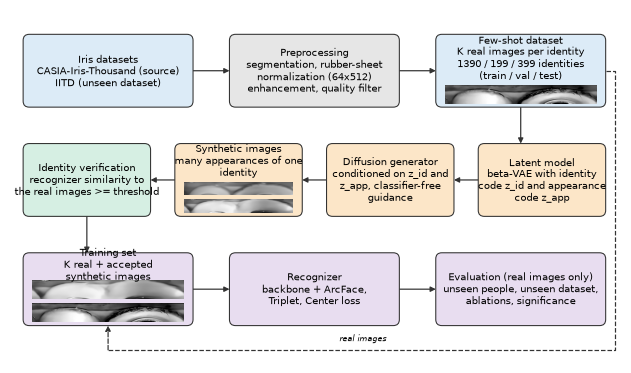

Saved: fig01_pipeline


In [7]:
# ============================================================
# 7. Figure 1: pipeline diagram
# ============================================================

STAGE = {"data": "#DCEBF7", "prep": "#E6E6E6", "gen": "#FCE6C8", "verify": "#D6EFE3", "model": "#E8DDF0"}


def tag(text):
    return f" ({text})" if SHOW_NOTEBOOK_TAGS else ""


def draw_box(ax, x, y, w, h, text, color, thumbs=()):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.0", linewidth=0.7, edgecolor="#333333", facecolor=color, zorder=2))
    thumb_h = (w - 3.0) / 8.0
    reserved = len(thumbs) * (thumb_h + 0.6) + (0.6 if thumbs else 0.0)
    ax.text(x + w / 2, y + reserved + (h - reserved) / 2, text, ha="center", va="center", fontsize=FONT_SIZE - 1.5, zorder=4, linespacing=1.2)
    for k, image in enumerate(thumbs):
        y0 = y + 0.6 + k * (thumb_h + 0.6)
        ax.imshow(image, cmap="gray", vmin=0, vmax=255, extent=(x + 1.5, x + w - 1.5, y0, y0 + thumb_h), zorder=3, aspect="equal")


def arrow(ax, p, q, dashed=False):
    ax.annotate("", xy=q, xytext=p, zorder=1, arrowprops=dict(arrowstyle="-|>", lw=0.8, color="#333333", mutation_scale=7,
                                                              linestyle="--" if dashed else "-", shrinkA=0, shrinkB=0))


def elbow(ax, points, dashed=False):
    xs, ys = zip(*points[:-1])
    ax.plot(xs, ys, color="#333333", lw=0.8, linestyle="--" if dashed else "-", zorder=1)
    arrow(ax, points[-2], points[-1], dashed)


def make_pipeline():
    shot = int(long_manifest["shot"].min()) if STATS_SHOT is None else int(STATS_SHOT)
    per_class = long_manifest[long_manifest["shot"] == shot].drop_duplicates("class_id")
    counts = {s: int(((per_class["dataset"] == source_dataset) & (per_class["split"] == s)).sum()) for s in ("train", "val", "test")}

    real_thumbs, gen_thumbs = [], []
    try:
        train_ids = sorted(per_class.loc[(per_class["dataset"] == source_dataset) & (per_class["split"] == "train"), "class_id"])
        real_thumbs = real_strips(shot, train_ids[0], 2) if train_ids else []
    except Exception:
        real_thumbs = []
    try:
        pool, _ = generated_pool("all")
        gen_thumbs = [read_gray(GENERATED_DIR / p) for p in pool.sort_values(["shot", "class_id", "synth_index"])["relative_path"].head(2)]
    except Exception:
        gen_thumbs = []

    fig, ax = plt.subplots(figsize=(PAGE_WIDTH, PAGE_WIDTH * 58 / 100.5))
    h, r1, r2, r3 = 12, 42, 24, 6
    row13 = [2, 36, 70]
    row2 = [77, 52, 27, 2]

    draw_box(ax, row13[0], r1, 28, h, "Iris datasets\nCASIA-Iris-Thousand (source)\nIITD (unseen dataset)", STAGE["data"])
    draw_box(ax, row13[1], r1, 28, h, "Preprocessing" + tag("N02-N05") + "\nsegmentation, rubber-sheet\nnormalization (64x512)\nenhancement, quality filter", STAGE["prep"])
    draw_box(ax, row13[2], r1, 28, h, "Few-shot dataset" + tag("N06") + f"\nK real images per identity\n{counts['train']} / {counts['val']} / {counts['test']} identities\n(train / val / test)", STAGE["data"], real_thumbs)
    draw_box(ax, row2[0], r2, 21, h, "Latent model" + tag("N08") + "\nbeta-VAE with identity\ncode z_id and appearance\ncode z_app", STAGE["gen"])
    draw_box(ax, row2[1], r2, 21, h, "Diffusion generator" + tag("N09") + "\nconditioned on z_id and\nz_app, classifier-free\nguidance", STAGE["gen"])
    draw_box(ax, row2[2], r2, 21, h, "Synthetic images" + tag("N10") + "\nmany appearances of one\nidentity", STAGE["gen"], gen_thumbs)
    draw_box(ax, row2[3], r2, 21, h, "Identity verification" + tag("N11") + "\nrecognizer similarity to\nthe real images >= threshold", STAGE["verify"])
    draw_box(ax, row13[0], r3, 28, h, "Training set\nK real + accepted\nsynthetic images", STAGE["model"], [t for t in (real_thumbs[:1] + gen_thumbs[:1])])
    draw_box(ax, row13[1], r3, 28, h, "Recognizer" + tag("N13") + "\nbackbone + ArcFace,\nTriplet, Center loss", STAGE["model"])
    draw_box(ax, row13[2], r3, 28, h, "Evaluation (real images only)\nunseen people, unseen dataset,\nablations, significance", STAGE["model"])

    arrow(ax, (30, 48), (36, 48))
    arrow(ax, (64, 48), (70, 48))
    arrow(ax, (84, r1), (84, r2 + h))                                   # few-shot dataset -> latent model
    arrow(ax, (row2[0], 30), (row2[1] + 21, 30))                        # right to left through the second row
    arrow(ax, (row2[1], 30), (row2[2] + 21, 30))
    arrow(ax, (row2[2], 30), (row2[3] + 21, 30))
    arrow(ax, (12.5, r2), (12.5, r3 + h))                               # accepted images -> training set
    arrow(ax, (30, 12), (36, 12))
    arrow(ax, (64, 12), (70, 12))
    elbow(ax, [(98, 48), (99.6, 48), (99.6, 2.0), (16, 2.0), (16, r3)], dashed=True)    # real images -> training set
    ax.text(58, 3.1, "real images", fontsize=FONT_SIZE - 2.5, ha="center", va="bottom", style="italic")

    ax.set_xlim(0, 100.5)
    ax.set_ylim(0, 58)
    ax.axis("off")
    caption = ("Overview of the proposed pipeline. Real iris images are preprocessed into normalized texture strips and split into a few-shot dataset "
               "(K real images per identity, subject-level splits). A latent model separates an identity code from an appearance code; a diffusion generator "
               "conditioned on both produces many images of the same identity, which an identity verifier filters against the real images. "
               "The recognizer is trained on the real images plus the accepted synthetic images and evaluated on real images only, "
               "on unseen people and on an unseen dataset.")
    save_figure(fig, "fig01_pipeline", caption, "Notebook 06 manifest, Notebook 10 manifest (counts and thumbnails)")


run_figure("pipeline", make_pipeline)

## 8. Figure 2: dataset statistics

Four panels: (a) identities per split and dataset, (b) real images per identity (support plus query) at `STATS_SHOT`, (c) the composite quality score of every image of Notebook 05 per dataset with the quality threshold, (d) accepted synthetic images per identity (Notebook 11). Panels (c) and (d) show a note instead of data if their input is missing. The table `dataset_statistics.csv` lists identities and images per shot, dataset, split, and role.

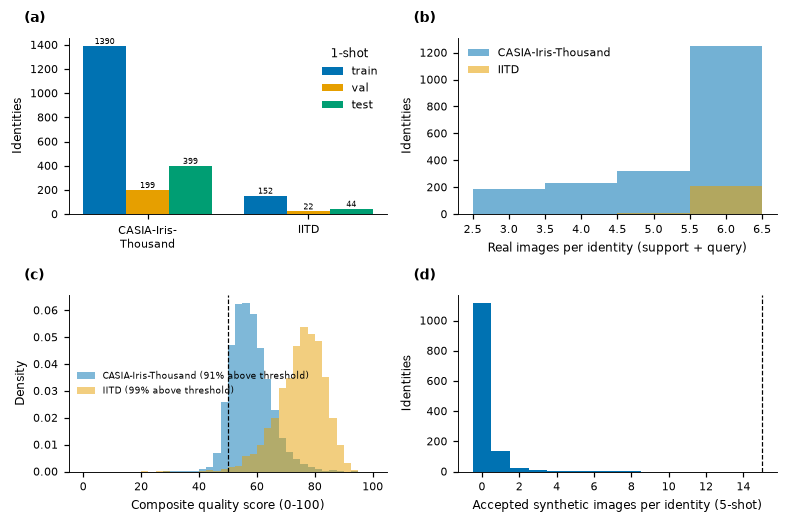

Saved: fig02_dataset_statistics


,shot,dataset,split,identities,query,support
0,1,CASIA-Iris-Thousand,test,399,1730,399
1,1,CASIA-Iris-Thousand,train,1390,6000,1390
2,1,CASIA-Iris-Thousand,val,199,864,199
3,1,IITD,test,44,214,44
4,1,IITD,train,152,747,152
5,1,IITD,val,22,110,22
6,2,CASIA-Iris-Thousand,test,395,1722,790
7,2,CASIA-Iris-Thousand,train,1384,5988,2768
8,2,CASIA-Iris-Thousand,val,199,864,398
9,2,IITD,test,44,214,88


In [8]:
# ============================================================
# 8. Figure 2: dataset statistics
# ============================================================

def make_dataset_stats():
    shots_all = sorted(int(s) for s in long_manifest["shot"].unique())
    shot = STATS_SHOT if STATS_SHOT in shots_all else shots_all[0]

    per_class = long_manifest.drop_duplicates(["shot", "class_id"])
    ident = per_class.groupby(["shot", "dataset", "split"]).size().rename("identities").reset_index()
    images = long_manifest.groupby(["shot", "dataset", "split", "role"]).size().unstack("role", fill_value=0).reset_index()
    stats_table = ident.merge(images, on=["shot", "dataset", "split"], how="left")
    stats_table.to_csv(TABLE_DIR / "dataset_statistics.csv", index=False)

    sub = per_class[per_class["shot"] == shot]
    datasets = sorted(sub["dataset"].unique())
    splits = ["train", "val", "test"]
    fig, axes = plt.subplots(2, 2, figsize=(PAGE_WIDTH, 4.8))

    ax = axes[0, 0]
    width = 0.8 / len(splits)
    for k, split in enumerate(splits):
        heights = [int(((sub["dataset"] == d) & (sub["split"] == split)).sum()) for d in datasets]
        bars = ax.bar(np.arange(len(datasets)) + (k - 1) * width, heights, width, label=split, color=SERIES_COLORS[k])
        for bar, value in zip(bars, heights):
            if value:
                ax.text(bar.get_x() + bar.get_width() / 2, value, str(value), ha="center", va="bottom", fontsize=FONT_SIZE - 2.5)
    ax.set_xticks(np.arange(len(datasets)))
    ax.set_xticklabels([wrap(d, 14) for d in datasets])
    ax.set_ylabel("Identities")
    ax.legend(frameon=False, title=f"{shot}-shot")
    panel_label(ax, "a")

    ax = axes[0, 1]
    per_identity = long_manifest[long_manifest["shot"] == shot].groupby(["dataset", "class_id"]).size().rename("n").reset_index()
    lo, hi = int(per_identity["n"].min()), int(per_identity["n"].max())
    bins = np.linspace(lo - 0.5, hi + 0.5, min(hi - lo + 2, 31))
    for i, d in enumerate(datasets):
        ax.hist(per_identity.loc[per_identity["dataset"] == d, "n"], bins=bins, histtype="stepfilled", alpha=0.55, color=SERIES_COLORS[i], label=d)
    ax.set_xlabel("Real images per identity (support + query)")
    ax.set_ylabel("Identities")
    ax.legend(frameon=False)
    panel_label(ax, "b")

    ax = axes[1, 0]
    quality_note = ""
    if quality_scores is not None and {"dataset", QUALITY_COLUMN} <= set(quality_scores.columns):
        for i, d in enumerate(sorted(quality_scores["dataset"].unique())):
            values = quality_scores.loc[quality_scores["dataset"] == d, QUALITY_COLUMN].to_numpy(dtype=float)
            values = values[np.isfinite(values)]
            if len(values):
                ax.hist(values, bins=40, range=(0, 100), density=True, histtype="stepfilled", alpha=0.5, color=SERIES_COLORS[i],
                        label=f"{d} ({100 * np.mean(values >= QUALITY_THRESHOLD):.0f}% above threshold)")
        ax.axvline(QUALITY_THRESHOLD, color="black", linestyle="--", linewidth=0.8)
        ax.set_xlabel("Composite quality score (0-100)")
        ax.set_ylabel("Density")
        ax.legend(frameon=False, fontsize=FONT_SIZE - 2)
        quality_note = " (c) shows the composite quality score of all images; the dashed line is the quality threshold."
        panel_label(ax, "c")
    else:
        ax.text(0.5, 0.5, "Notebook 05 quality scores\nnot available", transform=ax.transAxes, ha="center", va="center")
        ax.axis("off")

    ax = axes[1, 1]
    accept_note = ""
    if identity_acceptance is not None and {"shot", "n_accepted", "n_synthetic"} <= set(identity_acceptance.columns):
        shot_a = choose_shot(identity_acceptance["shot"].unique())
        acc = identity_acceptance[identity_acceptance["shot"] == shot_a]
        top = int(acc["n_accepted"].max())
        ax.hist(acc["n_accepted"], bins=np.arange(-0.5, top + 1.5, 1) if top <= 60 else 30, color=BLUE)
        ax.axvline(float(acc["n_synthetic"].mean()), color="black", linestyle="--", linewidth=0.8)
        ax.set_xlabel(f"Accepted synthetic images per identity ({shot_a}-shot)")
        ax.set_ylabel("Identities")
        accept_note = f" (d) shows how many of the {acc['n_synthetic'].mean():.0f} generated images per identity were accepted by identity verification (dashed line: generated)."
        panel_label(ax, "d")
    else:
        ax.text(0.5, 0.5, "Notebook 11 identity acceptance\nnot available", transform=ax.transAxes, ha="center", va="center")
        ax.axis("off")

    fig.tight_layout()
    caption = (f"Dataset statistics. (a) Identities per split of each dataset ({shot}-shot setting; splits are by person). "
               f"(b) Number of real images available per identity.{quality_note}{accept_note}")
    save_figure(fig, "fig02_dataset_statistics", caption, "Notebook 06 manifest, Notebook 05 quality scores, Notebook 11 identity acceptance")
    display(stats_table.head(12))


run_figure("dataset", make_dataset_stats)

## 9. Figure 3: sample synthetic images

Several identities, each as a block of stacked 64 x 512 strips: the real enrolled images (blue bar) on top, and generated images of the same identity (orange bar) below, chosen evenly by index. `SAMPLE_SOURCE = "accepted"` uses the images accepted by Notebook 11 (the caption says "verified"); if they are not available, all generated images are used and the caption says "unfiltered". The identities used are saved in `samples_used.csv`.

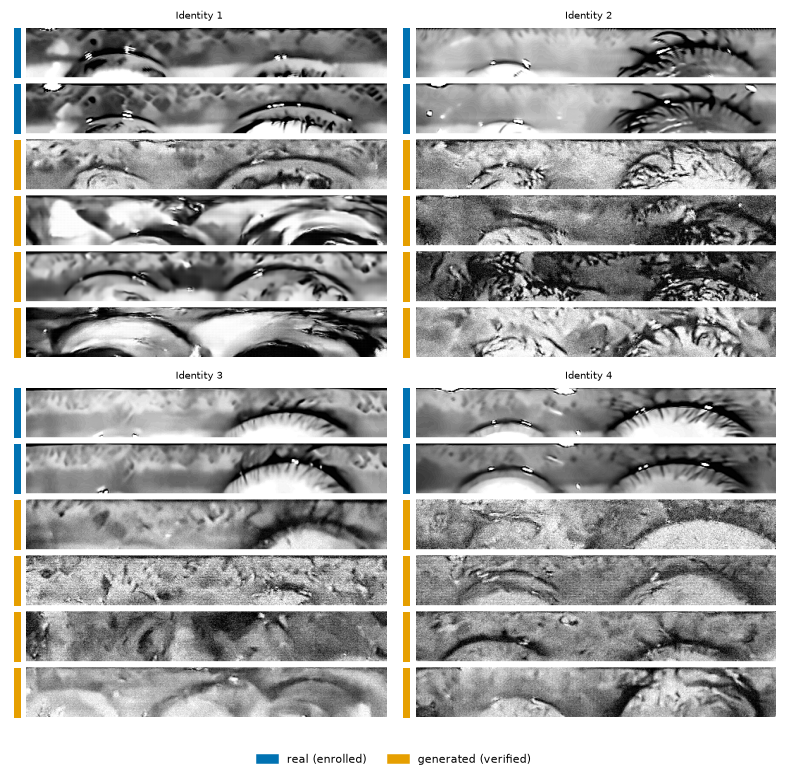

Saved: fig03_sample_synthetic_images


In [9]:
# ============================================================
# 9. Figure 3: sample synthetic images
# ============================================================

def make_samples():
    pool_all, label = generated_pool(SAMPLE_SOURCE)
    pool_all = pool_all.copy()
    shot = choose_shot(pool_all["shot"].unique())
    pool = pool_all[pool_all["shot"] == shot]
    if "generator_run_id" in pool.columns:
        pool = pool[pool["generator_run_id"] == f"diffusion__{shot}shot__seed{GENERATOR_SEED}"]

    support = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["role"] == "support") & (long_manifest["split"] == "train")
                            & (long_manifest["dataset"] == source_dataset)]
    n_real, n_gen = support.groupby("class_id").size(), pool.groupby("class_id").size()
    eligible = sorted(set(n_real[n_real >= SAMPLE_REAL].index) & set(n_gen[n_gen >= SAMPLE_GENERATED].index))
    if not eligible:
        raise SkipFigure(f"no identity has {SAMPLE_REAL} real and {SAMPLE_GENERATED} generated images at {shot}-shot")

    chosen = pick_evenly(eligible, SAMPLE_IDENTITIES)
    blocks, used = [], []
    for k, class_id in enumerate(chosen, start=1):
        real = real_strips(shot, class_id, SAMPLE_REAL)
        gen_rows = pool[pool["class_id"] == class_id].sort_values("synth_index")
        gen_rows = gen_rows.iloc[np.unique(np.linspace(0, len(gen_rows) - 1, SAMPLE_GENERATED).round().astype(int))]
        generated = [read_gray(GENERATED_DIR / p) for p in gen_rows["relative_path"]]
        blocks.append(([(s, BLUE) for s in real] + [(s, ORANGE) for s in generated], f"Identity {k}"))
        used.append({"identity": k, "class_id": class_id, "shot": shot, "real_images": len(real), "generated_images": ", ".join(gen_rows["relative_path"])})

    n_cols = 2 if len(blocks) > 1 else 1
    n_rows = math.ceil(len(blocks) / n_cols)
    n_strips = SAMPLE_REAL + SAMPLE_GENERATED
    block_height = n_strips * 64 + (n_strips - 1) * 8
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(PAGE_WIDTH, n_rows * (PAGE_WIDTH / n_cols * block_height / 534 + 0.45) + 0.4), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for ax, (items, title) in zip(axes.flatten(), blocks):
        draw_block(ax, items, title)

    fig.legend(handles=[Patch(color=BLUE, label="real (enrolled)"), Patch(color=ORANGE, label=f"generated ({label})")], loc="lower center", ncol=2, frameon=False)
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    caption = (f"Real iris textures (blue) and {label} synthetic images (orange) of the same identity, {shot}-shot setting. "
               "The generated images keep the identity while rotation, illumination, pupil dilation, blur, and noise vary. "
               "The generated images shown are spread evenly over the index of the identity's images, not hand-picked.")
    save_figure(fig, "fig03_sample_synthetic_images", caption, "Notebook 06 manifest, Notebook 10 / 11 generated images")
    pd.DataFrame(used).to_csv(TABLE_DIR / "samples_used.csv", index=False)


run_figure("samples", make_samples)

## 10. Figure 4: embedding visualizations

The 2-D coordinates of Notebook 15 (t-SNE and UMAP, or the PCA fallback) are drawn for the models in `EMBED_MODEL_KEYS`: **colour = person**, **marker = kind of image** (real support X, real held-out o, synthetic dot, unseen-person support star and query diamond). Each panel title shows the projection that was actually used and its quality: the neighbour recall (how well local neighbourhoods are kept) and the identity purity (share of points whose nearest neighbour has the same identity) in 2-D. **Read clusters, not distances between clusters.**

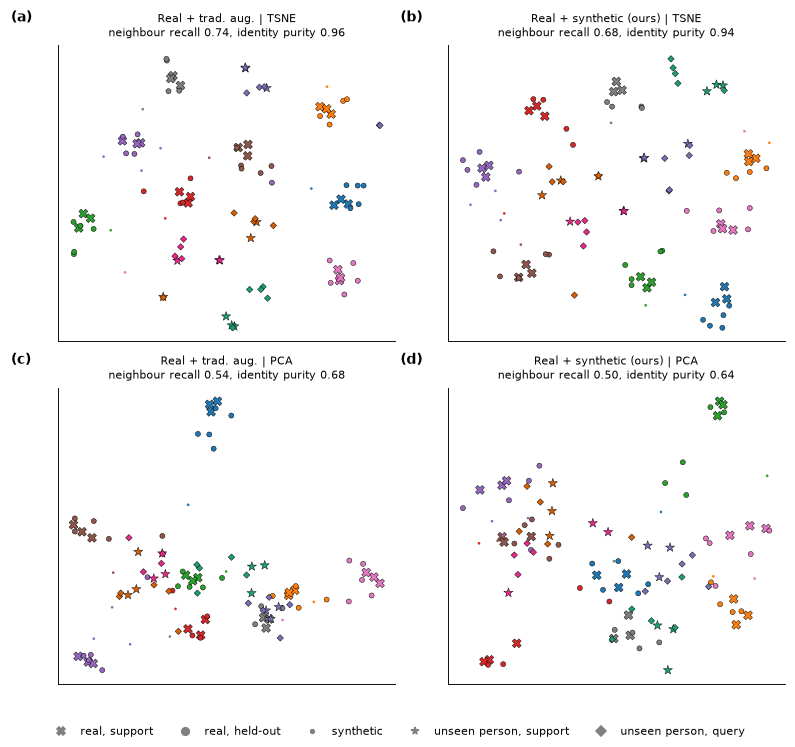

Saved: fig04_embedding_visualizations


In [10]:
# ============================================================
# 10. Figure 4: embedding visualizations
# ============================================================

KIND_STYLE = {"support": ("X", 34, "real, support"), "query": ("o", 11, "real, held-out"), "synthetic": (".", 12, "synthetic"),
              "unseen_support": ("*", 40, "unseen person, support"), "unseen_query": ("D", 9, "unseen person, query")}


def make_embeddings():
    if proj_coords is None:
        raise SkipFigure("Notebook 15's projection_coordinates.csv was not found")
    shot = choose_shot(proj_coords["shot"].unique())
    data = proj_coords[proj_coords["shot"] == shot]
    keys = [k for k in EMBED_MODEL_KEYS if k in set(data["model_key"])] or list(dict.fromkeys(data["model_key"]))
    methods = [m for m in (EMBED_METHODS or list(dict.fromkeys(data["method"]))) if m in set(data["method"])]
    if not keys or not methods:
        raise SkipFigure("no model or method of the request is in the projection file")

    unseen = set(data.loc[data["kind"].isin(["unseen_support", "unseen_query"]), "class_id"])
    colors = {c: plt.cm.tab10(i % 10) for i, c in enumerate(sorted(set(data["class_id"]) - unseen))}
    colors.update({c: plt.cm.Dark2(i % 8) for i, c in enumerate(sorted(unseen))})

    fig, axes = plt.subplots(len(methods), len(keys), figsize=(PAGE_WIDTH, 3.1 * len(methods) + 0.55), squeeze=False)
    letters = iter("abcdefgh")
    for r, method in enumerate(methods):
        for c, key in enumerate(keys):
            ax = axes[r, c]
            sub = data[(data["model_key"] == key) & (data["method"] == method)]
            for kind, (marker, size, _) in KIND_STYLE.items():
                part = sub[sub["kind"] == kind]
                if len(part):
                    ax.scatter(part["x"], part["y"], marker=marker, s=size, c=[colors[k] for k in part["class_id"]],
                               edgecolors="none" if kind == "synthetic" else "black", linewidths=0.3)
            used, detail = method, ""
            if proj_quality is not None:
                q = proj_quality[(proj_quality["shot"] == shot) & (proj_quality["model_key"] == key) & (proj_quality["method"] == method)]
                if len(q):
                    used = str(q["method_used"].iloc[0])
                    detail = f"\nneighbour recall {float(q['neighbor_recall'].iloc[0]):.2f}, identity purity {float(q['label_1nn_2d'].iloc[0]):.2f}"
            ax.set_title(f"{SHORT_LABELS.get(key, key)} | {used.upper()}{detail}", fontsize=FONT_SIZE - 1)
            ax.set_xticks([])
            ax.set_yticks([])
            panel_label(ax, next(letters))

    handles = [Line2D([0], [0], marker=m, color="gray", linestyle="", markersize=5, label=l) for k, (m, _, l) in KIND_STYLE.items() if bool((data["kind"] == k).any())]
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 5), frameon=False)
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    caption = (f"Embeddings of real and synthetic images ({shot}-shot setting) projected to two dimensions. Colour marks the person, the marker the kind of image. "
               "Training people are drawn with the tab10 palette, unseen people with a second palette. Panel titles give the neighbour recall and the identity purity of each "
               "projection; distances between clusters carry no meaning.")
    save_figure(fig, "fig04_embedding_visualizations", caption, "Notebook 15 projection_coordinates.csv, projection_quality.csv")


from matplotlib.lines import Line2D
run_figure("embeddings", make_embeddings)

## 11. Figure 5: ROC and DET curves

Top row: ROC curves (true accept rate against false accept rate, log axis). Bottom row: DET curves (false reject rate against false accept rate on normal-deviate axes, so that better systems lie lower and to the left). One column per evaluation set (the unseen people of the source dataset, and the unseen dataset), one curve per kind of model, at `FIGURE_SHOT`. The legend gives each model's EER. The curves are the fixed false-accept grid stored by Notebook 14; the shaded band is the minimum to maximum over seeds (none with one seed).

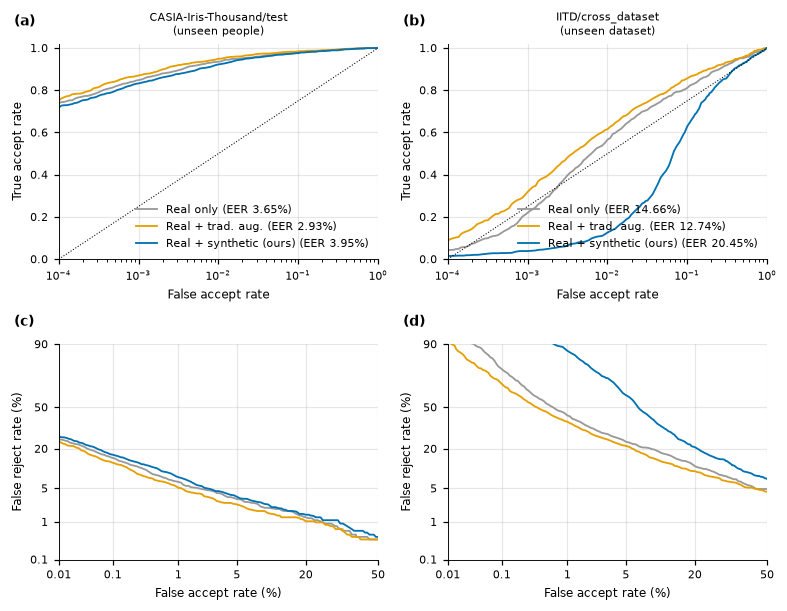

Saved: fig05_roc_det


In [11]:
# ============================================================
# 11. Figure 5: ROC and DET curves
# ============================================================

DET_FAR_TICKS = [1e-4, 1e-3, 1e-2, 5e-2, 0.2, 0.5]
DET_FRR_TICKS = [1e-3, 1e-2, 5e-2, 0.2, 0.5, 0.9]


def set_title(eval_set):
    return f"{eval_set}\n({'unseen people' if set_kind.get(eval_set) == 'within_dataset_test' else 'unseen dataset'})"


def make_roc_det():
    if results_chosen is None or roc14 is None:
        raise SkipFigure("Notebook 14's results or ROC grids were not found")
    roc = roc14.merge(chosen14[CONFIG_KEYS], on=CONFIG_KEYS, how="inner")
    roc = roc[roc["eval_set"].isin(eval_sets)]
    if len(roc) == 0:
        raise SkipFigure("no ROC grid belongs to the chosen models")
    shot = choose_shot(roc["shot"].unique())
    roc = roc[roc["shot"] == shot]
    curves = roc.groupby(["group", "eval_set", "fpr"], as_index=False)["tpr"].agg(tpr="mean", lo="min", hi="max")
    eers = results_chosen[results_chosen["shot"] == shot].groupby(["group", "eval_set"])["eer"].mean()
    sets_here = [s for s in eval_sets if s in set(curves["eval_set"])]

    fig, axes = plt.subplots(2, len(sets_here), figsize=(PAGE_WIDTH, 5.6), squeeze=False)
    for c, eval_set in enumerate(sets_here):
        for group in GROUP_ORDER:
            sub = curves[(curves["group"] == group) & (curves["eval_set"] == eval_set) & (curves["fpr"] > 0)].sort_values("fpr")
            if len(sub) == 0:
                continue
            fpr, tpr, lo, hi = (sub[k].to_numpy() for k in ("fpr", "tpr", "lo", "hi"))
            eer = eers.get((group, eval_set), np.nan)
            label = SHORT_LABELS[group] + (f" (EER {100 * eer:.2f}%)" if np.isfinite(eer) else "")
            axes[0, c].plot(fpr, tpr, color=GROUP_COLORS[group], label=label)
            axes[1, c].plot(probit(fpr), probit(1.0 - tpr), color=GROUP_COLORS[group])
            if float(np.max(hi - lo)) > 1e-9:
                axes[0, c].fill_between(fpr, lo, hi, color=GROUP_COLORS[group], alpha=0.18, linewidth=0)
                axes[1, c].fill_between(probit(fpr), probit(1.0 - hi), probit(1.0 - lo), color=GROUP_COLORS[group], alpha=0.18, linewidth=0)

        ax = axes[0, c]
        ax.plot([1e-4, 1], [1e-4, 1], ":", color="black", linewidth=0.7)
        ax.set_xscale("log")
        ax.set_xlim(1e-4, 1)
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("False accept rate")
        ax.set_ylabel("True accept rate")
        ax.set_title(set_title(eval_set), fontsize=FONT_SIZE - 1)
        ax.legend(loc="lower right", frameon=False)
        ax.grid(alpha=0.3)

        ax = axes[1, c]
        ax.set_xticks(probit(DET_FAR_TICKS))
        ax.set_xticklabels([f"{100 * t:g}" for t in DET_FAR_TICKS])
        ax.set_yticks(probit(DET_FRR_TICKS))
        ax.set_yticklabels([f"{100 * t:g}" for t in DET_FRR_TICKS])
        ax.set_xlim(probit(1e-4), probit(0.5))
        ax.set_ylim(probit(1e-3), probit(0.9))
        ax.set_xlabel("False accept rate (%)")
        ax.set_ylabel("False reject rate (%)")
        ax.grid(alpha=0.3)

    for ax, letter in zip(axes.flatten(), "abcdefgh"):
        panel_label(ax, letter)
    fig.tight_layout()
    caption = (f"ROC (top) and DET (bottom) curves of the models chosen with the validation people, {shot}-shot setting, on unseen people of the source dataset "
               "and on the unseen dataset. DET axes are normal deviates; lower and further left is better. The legend gives the equal error rate (EER). "
               "Shaded bands, where present, span the minimum to maximum over seeds.")
    save_figure(fig, "fig05_roc_det", caption, "Notebook 14 cross_dataset_roc.csv, cross_dataset_results.csv, cross_dataset_chosen_models.csv")


run_figure("roc_det", make_roc_det)

## 12. Figure 6: ablation charts

**(a) Ablation overview.** One panel per ablation group (generator, number of synthetic images, backbone, loss, quality filter). Horizontal bars show the **change in EER against the real-only model with the same backbone and loss** (percentage points; left of zero is better), for the unseen people and the unseen dataset. A star marks the arm of its group that has the lowest **validation** EER. The reference arms are not drawn (they are zero by definition).

**(b) Trend.** EER and Rank-1 against the number of synthetic images per identity actually used (zero = real only), from the count group. Skipped if there are fewer than two distinct counts.

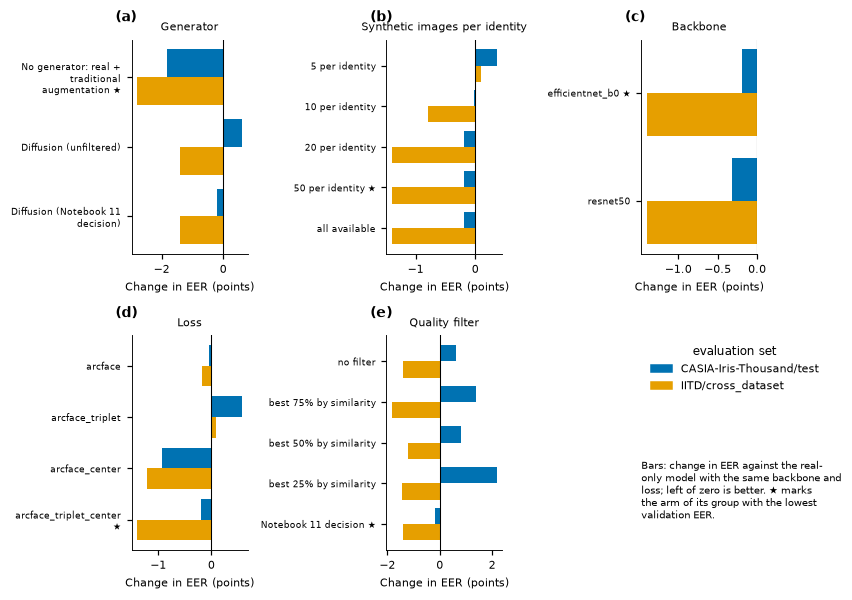

Saved: fig06a_ablation_charts


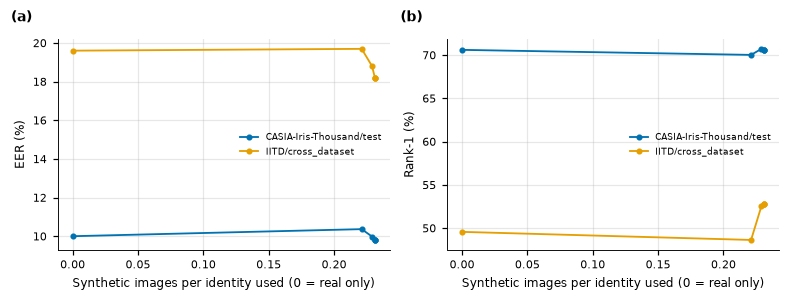

Saved: fig06b_ablation_trend


In [12]:
# ============================================================
# 12. Figure 6: ablation charts
# ============================================================

def ablation_frame(extra_columns=()):
    if ablation_report is None:
        raise SkipFigure("Notebook 16's ablation_report.csv was not found")
    need = {"group", "label", "shot", "eval_set", "kind", "is_reference"} | set(extra_columns)
    if need.difference(ablation_report.columns):
        raise SkipFigure(f"ablation_report.csv lacks columns {sorted(need.difference(ablation_report.columns))}")
    frame = ablation_report[ablation_report["kind"].isin(["within_dataset_test", "cross_dataset"])].copy()
    frame["is_reference"] = frame["is_reference"].astype(bool)
    return frame


def ordered_sets(frame):
    kinds = frame.drop_duplicates("eval_set").set_index("eval_set")["kind"].to_dict()
    return sorted(kinds, key=lambda s: (kinds[s] != "within_dataset_test", s))


def make_ablation():
    frame = ablation_frame(["eer_vs_real_only"])
    rep = frame[~frame["is_reference"] & frame["group"].isin(ABLATION_GROUP_ORDER) & np.isfinite(frame["eer_vs_real_only"])]
    if len(rep) == 0:
        raise SkipFigure("no ablation arm has a change in EER against real only")
    shot = choose_shot(rep["shot"].unique())
    rep = rep[rep["shot"] == shot]
    groups = [g for g in ABLATION_GROUP_ORDER if g in set(rep["group"])]
    abl_sets = ordered_sets(rep)

    n_cols = 3
    n_rows = math.ceil((len(groups) + 1) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(PAGE_WIDTH, 2.6 * n_rows + 0.3), squeeze=False)
    flat = list(axes.flatten())
    letters = iter("abcdefgh")

    for ax, group in zip(flat, groups):
        sub = rep[rep["group"] == group]
        arms = list(dict.fromkeys(sub["label"]))
        best = set(sub.loc[sub["best_by_validation"].astype(bool), "label"]) if "best_by_validation" in sub.columns else set()
        height = 0.8 / len(abl_sets)
        for k, eval_set in enumerate(abl_sets):
            values = []
            for arm in arms:
                row = sub[(sub["label"] == arm) & (sub["eval_set"] == eval_set)]
                values.append(100.0 * float(row["eer_vs_real_only"].iloc[0]) if len(row) else np.nan)
            ax.barh(np.arange(len(arms)) + (k - (len(abl_sets) - 1) / 2) * height, values, height, color=SERIES_COLORS[k % 3])
        ax.set_yticks(np.arange(len(arms)))
        ax.set_yticklabels([wrap(a + (" \u2605" if a in best else ""), 22) for a in arms], fontsize=FONT_SIZE - 2)
        ax.invert_yaxis()
        ax.axvline(0.0, color="black", linewidth=0.7)
        ax.set_xlabel("Change in EER (points)", fontsize=FONT_SIZE - 1)
        ax.set_title(ABLATION_TITLES[group], fontsize=FONT_SIZE - 1)
        panel_label(ax, next(letters))

    key_ax = flat[len(groups)]
    key_ax.axis("off")
    key_ax.legend(handles=[Patch(color=SERIES_COLORS[k % 3], label=s) for k, s in enumerate(abl_sets)], loc="upper left", frameon=False, title="evaluation set")
    key_ax.text(0.0, 0.42, wrap("Bars: change in EER against the real-only model with the same backbone and loss; left of zero is better. "
                                 "\u2605 marks the arm of its group with the lowest validation EER.", 38), transform=key_ax.transAxes, va="top", fontsize=FONT_SIZE - 1.5)
    for ax in flat[len(groups) + 1:]:
        ax.axis("off")

    fig.tight_layout()
    caption = (f"Ablation study ({shot}-shot setting). Each panel varies one factor of the method and shows the change in EER against the real-only model with the same "
               "backbone and loss (percentage points; negative is better) on unseen people and on the unseen dataset. Stars mark the arm with the lowest validation EER in its group.")
    save_figure(fig, "fig06a_ablation_charts", caption, "Notebook 16 ablation_report.csv")


def make_ablation_trend():
    frame = ablation_frame(["eer", "rank1_acc", "synthetic_per_identity", "backbone", "loss"])
    rep = frame[(frame["group"] == "count") & ~frame["is_reference"]]
    if len(rep) == 0 or rep["synthetic_per_identity"].nunique() < 2:
        raise SkipFigure("the count group has fewer than two distinct numbers of synthetic images")
    shot = choose_shot(rep["shot"].unique())
    rep, refs = rep[rep["shot"] == shot], frame[frame["is_reference"] & (frame["shot"] == shot)]
    abl_sets = ordered_sets(rep)

    fig, axes = plt.subplots(1, 2, figsize=(PAGE_WIDTH, 2.8))
    for ax, (metric, title), letter in zip(axes, [("eer", "EER (%)"), ("rank1_acc", "Rank-1 (%)")], "ab"):
        for k, eval_set in enumerate(abl_sets):
            sub = rep[rep["eval_set"] == eval_set].sort_values("synthetic_per_identity")
            xs, ys = sub["synthetic_per_identity"].tolist(), (100 * sub[metric]).tolist()
            ref = refs[(refs["eval_set"] == eval_set) & (refs["backbone"] == sub["backbone"].iloc[0]) & (refs["loss"] == sub["loss"].iloc[0])]
            if len(ref):
                xs, ys = [0.0] + xs, [100 * float(ref[metric].iloc[0])] + ys
            ax.plot(xs, ys, marker="o", markersize=3, color=SERIES_COLORS[k % 3], label=eval_set)
        ax.set_xlabel("Synthetic images per identity used (0 = real only)")
        ax.set_ylabel(title)
        ax.legend(frameon=False, fontsize=FONT_SIZE - 2)
        ax.grid(alpha=0.3)
        panel_label(ax, letter)
    fig.tight_layout()
    caption = (f"Effect of the number of synthetic images per identity ({shot}-shot setting). The point at zero is the real-only model. "
               "The counts are those actually used; where fewer images existed than were requested, the arm is capped at the available number.")
    save_figure(fig, "fig06b_ablation_trend", caption, "Notebook 16 ablation_report.csv")


run_figure("ablation:overview", make_ablation)
run_figure("ablation:trend", make_ablation_trend)

## 13. Figure 7: cross-dataset comparison

At `FIGURE_SHOT`, for the models chosen with the validation people: (a) EER on unseen people (solid) against the unseen dataset (hatched), with the factor by which the EER grows; (b) the same for Rank-1; (c) EER on the unseen dataset against the number of enrolled images `K` (error bars with several seeds); (d) verification accuracy at the **threshold calibrated on the source validation people** (solid) against the best possible threshold on the unseen dataset (hatched): the gap is the cost of the threshold not transferring.

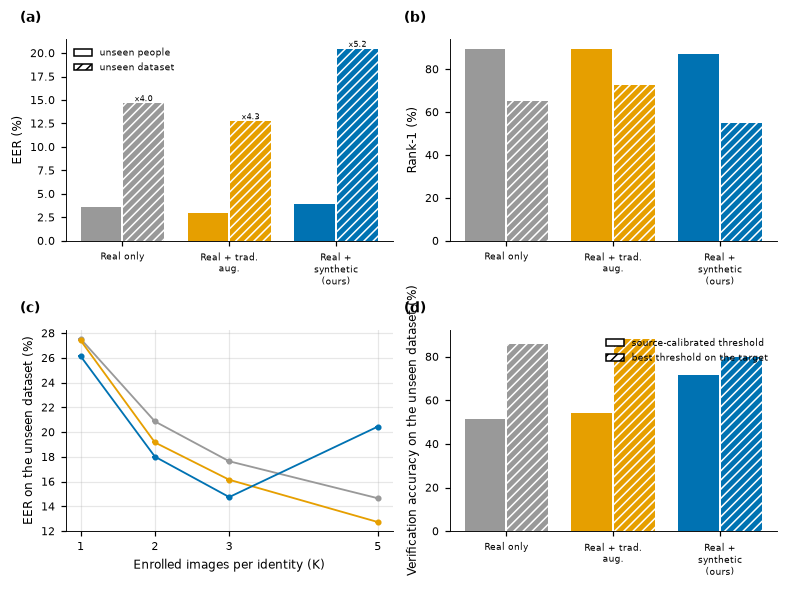

Saved: fig07_cross_dataset


In [13]:
# ============================================================
# 13. Figure 7: cross-dataset comparison
# ============================================================

def make_cross_dataset():
    if results_chosen is None:
        raise SkipFigure("Notebook 14's results were not found")
    within_sets = [e for e in eval_sets if set_kind[e] == "within_dataset_test"]
    cross_sets = [e for e in eval_sets if set_kind[e] == "cross_dataset"]
    if not within_sets or not cross_sets:
        raise SkipFigure("both the within-dataset test and an unseen-dataset result are needed")
    within, cross = within_sets[0], cross_sets[0]
    shot = choose_shot(results_chosen.loc[results_chosen["eval_set"] == cross, "shot"].unique())

    def at_shot(eval_set, metric):
        d = results_chosen[(results_chosen["eval_set"] == eval_set) & (results_chosen["shot"] == shot)]
        return d.groupby("group")[metric].mean()

    present = [g for g in GROUP_ORDER if g in set(results_chosen.loc[(results_chosen["eval_set"] == cross) & (results_chosen["shot"] == shot), "group"])]
    x = np.arange(len(present))
    colors = [GROUP_COLORS[g] for g in present]
    xticks = [wrap(SHORT_LABELS[g], 12) for g in present]
    fig, axes = plt.subplots(2, 2, figsize=(PAGE_WIDTH, 5.4))

    def paired(ax, first, second, metric_first, metric_second, ylabel, ratio=False):
        a, b = at_shot(first, metric_first), at_shot(second, metric_second)
        va, vb = [100 * a.get(g, np.nan) for g in present], [100 * b.get(g, np.nan) for g in present]
        ax.bar(x - 0.2, va, 0.38, color=colors)
        bars = ax.bar(x + 0.2, vb, 0.38, color=colors, hatch="////", edgecolor="white", linewidth=0)
        if ratio:
            for bar, p, q in zip(bars, va, vb):
                if np.isfinite(p) and np.isfinite(q) and p > 0:
                    ax.text(bar.get_x() + bar.get_width() / 2, q, f"x{q / p:.1f}", ha="center", va="bottom", fontsize=FONT_SIZE - 2.5)
        ax.set_xticks(x)
        ax.set_xticklabels(xticks, fontsize=FONT_SIZE - 2)
        ax.set_ylabel(ylabel)

    paired(axes[0, 0], within, cross, "eer", "eer", "EER (%)", ratio=True)
    axes[0, 0].legend(handles=[Patch(facecolor="white", edgecolor="black", label="unseen people"),
                               Patch(facecolor="white", edgecolor="black", hatch="////", label="unseen dataset")], frameon=False, fontsize=FONT_SIZE - 2)
    paired(axes[0, 1], within, cross, "rank1_acc", "rank1_acc", "Rank-1 (%)")

    ax = axes[1, 0]
    for group in present:
        d = results_chosen[(results_chosen["eval_set"] == cross) & (results_chosen["group"] == group)].groupby("shot")["eer"]
        mean, std = d.mean(), d.std(ddof=1)
        ax.errorbar(mean.index, 100 * mean.to_numpy(), yerr=100 * np.nan_to_num(std.to_numpy()), marker="o", markersize=3, capsize=2, color=GROUP_COLORS[group])
    ax.set_xticks(sorted(results_chosen.loc[results_chosen["eval_set"] == cross, "shot"].unique()))
    ax.set_xlabel("Enrolled images per identity (K)")
    ax.set_ylabel("EER on the unseen dataset (%)")
    ax.grid(alpha=0.3)

    ax = axes[1, 1]
    if {"verification_acc_src_eer", "verification_acc_oracle"} <= set(results_chosen.columns):
        paired(ax, cross, cross, "verification_acc_src_eer", "verification_acc_oracle", "Verification accuracy on the unseen dataset (%)")
        ax.legend(handles=[Patch(facecolor="white", edgecolor="black", label="source-calibrated threshold"),
                           Patch(facecolor="white", edgecolor="black", hatch="////", label="best threshold on the target")], frameon=False, fontsize=FONT_SIZE - 2)
    else:
        ax.text(0.5, 0.5, "verification accuracies\nnot in the results", transform=ax.transAxes, ha="center", va="center")
        ax.axis("off")

    for ax, letter in zip(axes.flatten(), "abcd"):
        panel_label(ax, letter)
    fig.tight_layout()

    final_w, final_c = at_shot(within, "eer").get("final_real_plus_synthetic", np.nan), at_shot(cross, "eer").get("final_real_plus_synthetic", np.nan)
    detail = f" For the proposed model the EER changes from {100 * final_w:.2f}% to {100 * final_c:.2f}%." if np.isfinite(final_w) and np.isfinite(final_c) else ""
    caption = (f"Cross-dataset comparison of models trained on {source_dataset} only ({shot}-shot setting). (a, b) EER and Rank-1 on unseen people of the source dataset "
               f"(solid) and on the unseen dataset (hatched); the factor above a bar is the growth of the EER.{detail} (c) EER on the unseen dataset against the number of "
               "enrolled images. (d) Verification accuracy at the threshold calibrated on the source validation people against the best threshold on the target.")
    save_figure(fig, "fig07_cross_dataset", caption, "Notebook 14 cross_dataset_results.csv, cross_dataset_chosen_models.csv")


run_figure("cross_dataset", make_cross_dataset)

## 14. Figure 8: qualitative failure cases

**Recognition failures** (needs PyTorch and the Notebook 13 best model): the best model is re-loaded, the test people (`FAILURE_POOL`) are enrolled with their support images, and every probe is scored. Two rows: **(top) the most confident wrong matches** and **(bottom) correct matches with the weakest same-person similarity**. Each case shows the probe, the enrolled image of the true identity (green bar), and the enrolled image of the most similar other identity (red bar), with both similarities and the image quality score if it can be linked. A second figure compares the **image quality of correctly and wrongly identified probes**.

**Generator failures** (needs Notebook 11's scores): synthetic images that identity verification **rejected**, shown next to a real image of the same identity: (top) the lowest similarity, (bottom) the closest to the threshold. Blank images are not shown but counted in the caption.

All cases are **selected by these criteria, not random**. The cases are saved to `failure_cases.csv` and `failure_generated.csv`.

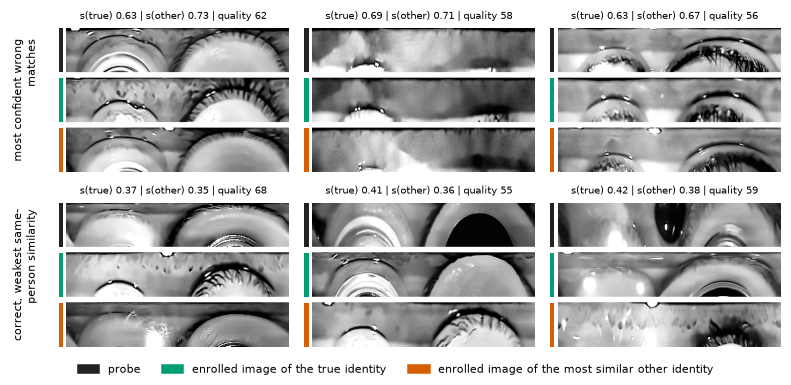

Saved: fig08a_failure_cases_recognition


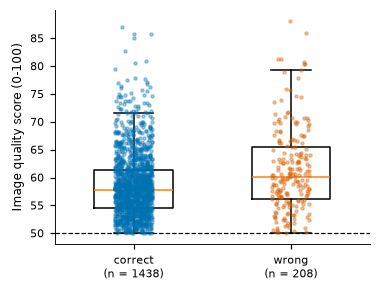

Saved: fig08b_failure_quality


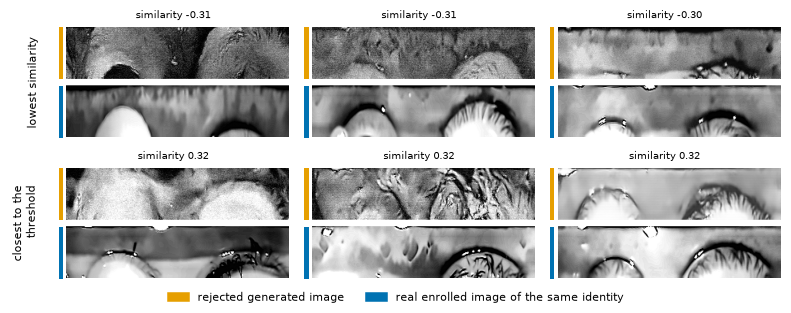

Saved: fig08c_failure_cases_generated


In [14]:
# ============================================================
# 14. Figure 8: qualitative failure cases
# ============================================================

KNOWN_BACKBONES = {"resnet50": (2048, False), "efficientnet_b0": (1280, False), "efficientnet_b3": (1536, False),
                   "efficientnet_v2_s": (1280, False), "convnext_tiny": (768, False), "swin_t": (768, True), "vit_b_16": (768, True)}

if TORCH_AVAILABLE:
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    def build_backbone(name):
        builder = getattr(tv_models, name, None)
        if builder is None:
            raise ValueError(f"torchvision has no model named '{name}'. Update torchvision.")
        backbone = builder(weights=None)
        if name.startswith("resnet"):
            backbone.fc = nn.Identity()
        elif name.startswith("efficientnet"):
            backbone.classifier = nn.Identity()
        elif name.startswith("convnext"):
            backbone.classifier[2] = nn.Identity()
        elif name.startswith("swin"):
            backbone.head = nn.Identity()
        elif name.startswith("vit"):
            backbone.heads = nn.Identity()
        else:
            raise ValueError(name)
        return backbone, KNOWN_BACKBONES[name][0], KNOWN_BACKBONES[name][1]

    class EmbeddingNet(nn.Module):
        def __init__(self, backbone_name, embedding_dim, square_size):
            super().__init__()
            self.backbone, feature_dim, self.needs_square = build_backbone(backbone_name)
            self.square_size = square_size
            self.embed = nn.Sequential(nn.Linear(feature_dim, embedding_dim), nn.BatchNorm1d(embedding_dim))
            self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
            self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        def forward(self, x):
            x = x.expand(-1, 3, -1, -1)
            x = (x - self.mean) / self.std
            if self.needs_square:
                x = F.interpolate(x, size=(self.square_size, self.square_size), mode="bilinear", align_corners=False)
            return self.embed(self.backbone(x))

    @torch.no_grad()
    def extract_embeddings(net, images_uint8, batch_size=128):
        net.eval()
        outputs = []
        for start in range(0, len(images_uint8), batch_size):
            batch = images_uint8[start:start + batch_size].to(DEVICE).float().div_(255.0).unsqueeze(1)
            outputs.append(F.normalize(net(batch).float(), dim=1).cpu())
        return torch.cat(outputs).numpy()


def load_best_model():
    if not TORCH_AVAILABLE:
        raise SkipFigure("PyTorch is not installed (needed for the recognition failure cases)")
    found = sorted(BEST_DIR.glob("best_*shot.pt")) if BEST_DIR.exists() else []
    if not found:
        raise SkipFigure(f"no best model found in {BEST_DIR} (run Notebook 13)")
    shot_of = lambda p: int(p.stem.split("_")[1].replace("shot", ""))
    wanted = BEST_DIR / f"best_{FIGURE_SHOT}shot.pt" if FIGURE_SHOT is not None else None
    path = wanted if wanted is not None and wanted.exists() else max(found, key=shot_of)
    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location="cpu")
    for key in ["model_state", "backbone", "embedding_dim", "input_hw", "vit_input_size", "shot", "train_classes"]:
        assert key in checkpoint, f"{path.name}: the checkpoint has no '{key}'"
    assert tuple(checkpoint["input_hw"]) == tuple(INPUT_HW), "the model was trained on a different image size"
    seen = {class_dataset.get(c, "UNKNOWN") for c in set(checkpoint["train_classes"])}
    assert "UNKNOWN" not in seen and seen <= {source_dataset}, f"the model was trained on {sorted(seen)}, not only on {source_dataset}"
    net = EmbeddingNet(checkpoint["backbone"], checkpoint["embedding_dim"], checkpoint["vit_input_size"])
    net.load_state_dict(checkpoint["model_state"])
    return net.to(DEVICE).eval(), checkpoint


def blocks_figure(rows, items_of, subtitle_of, row_titles, legend_handles, figure_height_strips):
    n_cols = FAILURE_CASES
    block_height = figure_height_strips * 64 + (figure_height_strips - 1) * 8
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(PAGE_WIDTH, len(rows) * (PAGE_WIDTH / n_cols * block_height / 534 + 0.55) + 0.5), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for r, indices in enumerate(rows):
        for c, index in enumerate(indices):
            draw_block(axes[r, c], items_of(index), subtitle_of(index))
        axes[r, 0].text(-0.08, 0.5, wrap(row_titles[r], 22), rotation=90, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=FONT_SIZE - 1)
    fig.legend(handles=legend_handles, loc="lower center", ncol=len(legend_handles), frameon=False)
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    return fig


def make_failures_recognition():
    net, checkpoint = load_best_model()
    shot = int(checkpoint["shot"])
    if FAILURE_POOL == "test":
        dataset, splits = source_dataset, ["test"]
    else:
        if not target_datasets:
            raise SkipFigure("FAILURE_POOL = 'cross' needs a dataset other than the source dataset")
        dataset, splits = target_datasets[0], list(TARGET_SPLITS)
    rows = long_manifest[(long_manifest["shot"] == shot) & (long_manifest["dataset"] == dataset) & (long_manifest["split"].isin(splits))]
    support, query = rows[rows["role"] == "support"].reset_index(drop=True), rows[rows["role"] == "query"].reset_index(drop=True)
    if len(support) == 0 or len(query) == 0:
        raise SkipFigure(f"no images for the failure pool at {shot}-shot")
    assert not (set(checkpoint["train_classes"]) & (set(support["class_id"]) | set(query["class_id"]))), "the model trained on an identity of the failure pool"

    support_images = np.stack([read_gray(resolve_real_path(r)) for _, r in support.iterrows()])
    query_images = np.stack([read_gray(resolve_real_path(r)) for _, r in query.iterrows()])
    emb_support, emb_query = extract_embeddings(net, torch.from_numpy(support_images)), extract_embeddings(net, torch.from_numpy(query_images))

    classes, inverse = np.unique(support["class_id"].to_numpy(), return_inverse=True)
    prototypes = np.zeros((len(classes), emb_support.shape[1]), dtype=np.float64)
    np.add.at(prototypes, inverse, emb_support.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)
    own = np.array([{c: i for i, c in enumerate(classes)}[c] for c in query["class_id"]])
    similarity = np.einsum("qd,cd->qc", emb_query.astype(np.float64), prototypes, optimize=False)

    q_index = np.arange(len(query))
    s_true = similarity[q_index, own]
    masked = similarity.copy()
    masked[q_index, own] = -np.inf
    other, s_other = masked.argmax(axis=1), masked.max(axis=1)
    correct = s_true > s_other
    first_support = {}
    for i, c in enumerate(support["class_id"]):
        first_support.setdefault(c, i)

    wrong = np.flatnonzero(~correct)
    wrong = wrong[np.argsort(-s_other[wrong])][:FAILURE_CASES]
    weak = np.flatnonzero(correct)
    weak = weak[np.argsort(s_true[weak])][:FAILURE_CASES]
    categories = [(t, idx) for t, idx in [("most confident wrong matches", wrong), ("correct, weakest same-person similarity", weak)] if len(idx)]
    if not categories:
        raise SkipFigure("no probes to show")

    qualities = np.array([quality_of(p) for p in query["source_path"]])

    def items_of(q):
        return [(query_images[q], "#222222"), (support_images[first_support[query["class_id"].iloc[q]]], GREEN),
                (support_images[first_support[classes[other[q]]]], VERMILLION)]

    def subtitle_of(q):
        return f"s(true) {s_true[q]:.2f} | s(other) {s_other[q]:.2f}" + (f" | quality {qualities[q]:.0f}" if np.isfinite(qualities[q]) else "")

    fig = blocks_figure([idx for _, idx in categories], items_of, subtitle_of, [t for t, _ in categories],
                        [Patch(color="#222222", label="probe"), Patch(color=GREEN, label="enrolled image of the true identity"),
                         Patch(color=VERMILLION, label="enrolled image of the most similar other identity")], 3)
    error_rate = float((~correct).mean())
    caption = (f"Failure cases of the final model ({shot}-shot, {dataset} {'/'.join(splits)} people; {100 * error_rate:.1f}% of {len(query)} probes are identified wrongly). "
               "Top: the wrong matches with the highest similarity. Bottom: correctly identified probes with the lowest similarity to their own identity. "
               "Each case shows the probe, an enrolled image of the true identity, and an enrolled image of the most similar other identity; s is the cosine similarity. "
               "The cases are selected by these criteria, not drawn at random.")
    save_figure(fig, "fig08a_failure_cases_recognition", caption, "Notebook 13 best model, Notebook 06 manifest, Notebook 05 quality scores")

    cases = [{"category": t, "probe_class": query["class_id"].iloc[q], "other_class": classes[other[q]], "s_true": float(s_true[q]),
              "s_other": float(s_other[q]), "quality": float(qualities[q]), "probe_source_path": query["source_path"].iloc[q]}
             for t, idx in categories for q in idx]
    pd.DataFrame(cases).to_csv(TABLE_DIR / "failure_cases.csv", index=False)

    finite = np.isfinite(qualities)
    if float(finite.mean()) >= MIN_QUALITY_LINKED and int((correct & finite).sum()) >= 5 and int((~correct & finite).sum()) >= 5:
        fig, ax = plt.subplots(figsize=(COLUMN_WIDTH, 2.7))
        groups = [qualities[correct & finite], qualities[~correct & finite]]
        ax.boxplot(groups, widths=0.5, showfliers=False)
        rng_j = np.random.default_rng(0)
        for k, values in enumerate(groups, start=1):
            ax.scatter(k + rng_j.uniform(-0.12, 0.12, len(values)), values, s=4, alpha=0.35, color=[BLUE, VERMILLION][k - 1], zorder=3)
        ax.axhline(QUALITY_THRESHOLD, color="black", linestyle="--", linewidth=0.8)
        ax.set_xticks([1, 2])
        ax.set_xticklabels([f"correct\n(n = {len(groups[0])})", f"wrong\n(n = {len(groups[1])})"])
        ax.set_ylabel("Image quality score (0-100)")
        fig.tight_layout()
        caption = (f"Image quality of correctly and wrongly identified probes ({shot}-shot, {dataset}). Boxes show the quartiles, points the individual probes, "
                   f"the dashed line the quality threshold. Median quality: {np.median(groups[0]):.1f} (correct) and {np.median(groups[1]):.1f} (wrong).")
        save_figure(fig, "fig08b_failure_quality", caption, "Notebook 13 best model, Notebook 05 quality scores")
    else:
        print(f"Quality figure skipped: quality scores are linked for {100 * float(finite.mean()):.0f}% of the probes (need {100 * MIN_QUALITY_LINKED:.0f}% and 5 cases in each group).")


def make_failures_generated():
    if verification_scores is None:
        raise SkipFigure("Notebook 11's verification_scores.csv was not found")
    need = {"shot", "class_id", "synth_index", "relative_path", "accepted", "degenerate", JUDGE_COLUMN}
    if need.difference(verification_scores.columns):
        raise SkipFigure(f"verification_scores.csv lacks columns {sorted(need.difference(verification_scores.columns))}")
    shot = choose_shot(verification_scores["shot"].unique())
    rows = verification_scores[verification_scores["shot"] == shot]
    if "generator_run_id" in rows.columns:
        rows = rows[rows["generator_run_id"] == f"diffusion__{shot}shot__seed{GENERATOR_SEED}"]
    rejected = rows[~rows["accepted"].astype(bool)]
    if len(rejected) == 0:
        raise SkipFigure("Notebook 11 accepted every generated image: there are no generator failures to show")
    usable = rejected[~rejected["degenerate"].astype(bool)]
    if len(usable) == 0:
        raise SkipFigure("only blank images were rejected")
    n_blank = len(rejected) - len(usable)

    lowest = usable.sort_values(JUDGE_COLUMN).head(FAILURE_CASES)
    closest = usable.sort_values(JUDGE_COLUMN, ascending=False).head(FAILURE_CASES)
    pairs = []
    for title, df in [("lowest similarity", lowest), ("closest to the threshold", closest)]:
        entries = []
        for _, r in df.iterrows():
            real = real_strips(shot, r["class_id"], 1)
            if real:
                entries.append({"row": r, "real": real[0], "generated": read_gray(GENERATED_DIR / r["relative_path"])})
        if entries:
            pairs.append((title, entries))
    if not pairs:
        raise SkipFigure("no real image was found for the rejected images' identities")

    threshold_text = ""
    if verification_calibration is not None and {"shot", "judge", "threshold"} <= set(verification_calibration.columns):
        t = verification_calibration[(verification_calibration["shot"] == shot) & (verification_calibration["judge"] == "recognizer")]
        if len(t):
            threshold_text = f" The decision threshold was {float(t['threshold'].iloc[0]):.2f}."

    entries_by_row = [e for _, e in pairs]
    fig = blocks_figure(range(len(pairs)), lambda ij: None, lambda ij: None, [t for t, _ in pairs], [], 2) if False else None
    n_cols = FAILURE_CASES
    block_height = 2 * 64 + 8
    fig, axes = plt.subplots(len(pairs), n_cols, figsize=(PAGE_WIDTH, len(pairs) * (PAGE_WIDTH / n_cols * block_height / 534 + 0.55) + 0.5), squeeze=False)
    for ax in axes.flatten():
        ax.axis("off")
    for r, (title, entries) in enumerate(pairs):
        for c, e in enumerate(entries[:n_cols]):
            draw_block(axes[r, c], [(e["generated"], ORANGE), (e["real"], BLUE)], f"similarity {float(e['row'][JUDGE_COLUMN]):.2f}")
        axes[r, 0].text(-0.08, 0.5, wrap(title, 22), rotation=90, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=FONT_SIZE - 1)
    fig.legend(handles=[Patch(color=ORANGE, label="rejected generated image"), Patch(color=BLUE, label="real enrolled image of the same identity")],
               loc="lower center", ncol=2, frameon=False)
    fig.tight_layout(rect=[0, 0.05, 1, 1])
    caption = (f"Generated images rejected by identity verification ({shot}-shot): the lowest-similarity rejections (top) and the rejections closest to the decision "
               f"threshold (bottom), each next to a real image of the same identity.{threshold_text} {len(rejected)} images were rejected, {n_blank} of them blank (not shown). "
               "The images are selected by these criteria, not drawn at random.")
    save_figure(fig, "fig08c_failure_cases_generated", caption, "Notebook 11 verification_scores.csv, Notebook 10 generated images")
    pd.DataFrame([{"category": t, "class_id": e["row"]["class_id"], "relative_path": e["row"]["relative_path"], "similarity": float(e["row"][JUDGE_COLUMN])}
                  for t, entries in pairs for e in entries]).to_csv(TABLE_DIR / "failure_generated.csv", index=False)


run_figure("failures:recognition", make_failures_recognition)
run_figure("failures:generated", make_failures_generated)

## 15. Captions and LaTeX

Every figure was registered with a caption built from the data, its sources, and its size. Three files are written:

| File | Content |
|---|---|
| `figure_manifest.csv` | Name, files, size, sources, and caption of every figure |
| `figure_captions.md` | The captions as readable text |
| `figures.tex` | One `figure` (or `figure*` for page-width figures) environment per figure with `\includegraphics`, the caption, and a label (`fig:<name>`); needs `\usepackage{graphicx}` and the figure files in a `figures/` folder next to the paper |

**Read each caption before using it:** it is generated from the results and describes the setting (shot, evaluation sets) but not your interpretation.

In [15]:
# ============================================================
# 15. Captions, manifest, and LaTeX
# ============================================================

LATEX_SPECIAL = {"&": r"\&", "%": r"\%", "$": r"\$", "#": r"\#", "_": r"\_", "{": r"\{", "}": r"\}"}


def latex_escape(text):
    text = str(text)
    for key, value in LATEX_SPECIAL.items():
        text = text.replace(key, value)
    return text.replace("\u2605", r"$\star$").replace("\u00b1", r"$\pm$")


assert latex_escape("5% x_y & z") == r"5\% x\_y \& z"

registry = pd.DataFrame(FIGURE_REGISTRY, columns=["name", "files", "width_in", "height_in", "sources", "caption", "quicktest"])
registry.to_csv(RESULTS_DIR / "figure_manifest.csv", index=False)

(RESULTS_DIR / "figure_captions.md").write_text(
    "\n\n".join(f"**{r.name}** ({r.files})\n\n{r.caption}\n\n*Sources: {r.sources}*" for r in registry.itertuples()) + "\n", encoding="utf-8")

lines = ["% Generated by Notebook 20. Needs \\usepackage{graphicx}; put the figure files in a figures/ folder next to the paper.", ""]
for r in registry.itertuples():
    files = r.files.split(", ")
    chosen_file = next((f for f in files if f.endswith(".pdf")), files[0])
    wide = r.width_in > COLUMN_WIDTH * 1.3
    environment, width = ("figure*", "\\textwidth") if wide else ("figure", "\\columnwidth")
    lines += ["\\begin{" + environment + "}[t]", "\\centering", "\\includegraphics[width=" + width + "]{figures/" + chosen_file + "}",
              "\\caption{" + latex_escape(r.caption) + "}", "\\label{fig:" + r.name + "}", "\\end{" + environment + "}", ""]
(RESULTS_DIR / "figures.tex").write_text("\n".join(lines), encoding="utf-8")

print("Saved: figure_manifest.csv, figure_captions.md, figures.tex")
display(registry[["name", "files", "width_in", "height_in", "sources"]].round(2))
print("\nFigure status:")
display(pd.DataFrame(FIGURE_STATUS))

Saved: figure_manifest.csv, figure_captions.md, figures.tex


,name,files,width_in,height_in,sources
0,fig01_pipeline,"fig01_pipeline.pdf, fig01_pipeline.png",7.2,4.16,"Notebook 06 manifest, Notebook 10 manifest (co..."
1,fig02_dataset_statistics,"fig02_dataset_statistics.pdf, fig02_dataset_st...",7.2,4.80,"Notebook 06 manifest, Notebook 05 quality scor..."
2,fig03_sample_synthetic_images,"fig03_sample_synthetic_images.pdf, fig03_sampl...",7.2,7.02,"Notebook 06 manifest, Notebook 10 / 11 generat..."
3,fig04_embedding_visualizations,"fig04_embedding_visualizations.pdf, fig04_embe...",7.2,6.75,"Notebook 15 projection_coordinates.csv, projec..."
4,fig05_roc_det,"fig05_roc_det.pdf, fig05_roc_det.png",7.2,5.60,"Notebook 14 cross_dataset_roc.csv, cross_datas..."
5,fig06a_ablation_charts,"fig06a_ablation_charts.pdf, fig06a_ablation_ch...",7.2,5.50,Notebook 16 ablation_report.csv
6,fig06b_ablation_trend,"fig06b_ablation_trend.pdf, fig06b_ablation_tre...",7.2,2.80,Notebook 16 ablation_report.csv
7,fig07_cross_dataset,"fig07_cross_dataset.pdf, fig07_cross_dataset.png",7.2,5.40,"Notebook 14 cross_dataset_results.csv, cross_d..."
8,fig08a_failure_cases_recognition,"fig08a_failure_cases_recognition.pdf, fig08a_f...",7.2,3.47,"Notebook 13 best model, Notebook 06 manifest, ..."
9,fig08b_failure_quality,"fig08b_failure_quality.pdf, fig08b_failure_qua...",3.5,2.70,"Notebook 13 best model, Notebook 05 quality sc..."



Figure status:


,figure,status,detail
0,pipeline,ok,
1,dataset,ok,
2,samples,ok,
3,embeddings,ok,
4,roc_det,ok,
5,ablation:overview,ok,
6,ablation:trend,ok,
7,cross_dataset,ok,
8,failures:recognition,ok,
9,failures:generated,ok,


## 16. Sanity checks

**Stop the notebook if:**
- any figure builder raised an error (missing inputs are skips, not errors);
- no figure was produced, a figure file is missing or empty, or its header is not a valid PDF / PNG / SVG;
- a figure has no caption, or two figures share a name;
- `figure_manifest.csv`, `figure_captions.md`, or `figures.tex` was not written.

**Warn if** (these describe expected behaviour, not guaranteed behaviour):
- a requested figure group was skipped (the reason is in the table above);
- a figure is wider than the page width plus half an inch;
- the figures come from QUICK_TEST (placeholders, not for publication).

In [16]:
# ============================================================
# 16. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


def valid_header(path):
    head = path.read_bytes()[:12]
    if path.suffix == ".pdf":
        return head.startswith(b"%PDF-")
    if path.suffix == ".png":
        return head[:8] == b"\x89PNG\r\n\x1a\n"
    return b"<?xml" in head or b"<svg" in head


errors = [s for s in FIGURE_STATUS if s["status"] == "error"]
add_check("no figure builder raised an error", not errors, "; ".join(f"{e['figure']}: {e['detail']}" for e in errors)[:300])
add_check("at least one figure was produced", len(FIGURE_REGISTRY) > 0)

files = [FIG_DIR / f for r in FIGURE_REGISTRY for f in r["files"].split(", ")]
missing = [f.name for f in files if not f.exists()]
add_check("every figure file exists", not missing, f"missing: {missing[:4]}")
broken = [f.name for f in files if f.exists() and (f.stat().st_size < 1000 or not valid_header(f))]
add_check("every figure file is non-empty and has a valid header", not broken, f"broken: {broken[:4]}")
add_check("every figure has a caption", all(len(r["caption"]) > 40 for r in FIGURE_REGISTRY))
add_check("figure names are unique", len({r["name"] for r in FIGURE_REGISTRY}) == len(FIGURE_REGISTRY))
add_check("the manifest, captions, and LaTeX files were written",
          all((RESULTS_DIR / n).exists() for n in ["figure_manifest.csv", "figure_captions.md", "figures.tex"]))

# ---- warnings ----
skipped = [s for s in FIGURE_STATUS if s["status"] == "skipped"]
add_check("no requested figure group was skipped", not skipped, "; ".join(f"{s['figure']} ({s['detail'][:60]})" for s in skipped)[:300], critical=False)
too_wide = [r["name"] for r in FIGURE_REGISTRY if r["width_in"] > PAGE_WIDTH + 0.5]
add_check("every figure fits the page width", not too_wide, f"wider than {PAGE_WIDTH + 0.5} in: {too_wide}", critical=False)
add_check("the figures come from real results (not QUICK_TEST)", not QUICK_TEST, "QUICK_TEST figures are placeholders", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "figure_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "figure_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical figure checks failed: {failed_names}"
print("\nFigure sanity checks completed with no critical failures.")

[PASS] no figure builder raised an error
[PASS] at least one figure was produced
[PASS] every figure file exists  (missing: [])
[PASS] every figure file is non-empty and has a valid header  (broken: [])
[PASS] every figure has a caption
[PASS] figure names are unique
[PASS] the manifest, captions, and LaTeX files were written
[PASS] no requested figure group was skipped
[PASS] every figure fits the page width  (wider than 7.7 in: [])
[PASS] the figures come from real results (not QUICK_TEST)  (QUICK_TEST figures are placeholders)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\paper_figures\figure_sanity_checks.csv

Figure sanity checks completed with no critical failures.


## 17. Final outputs

```text
results/paper_figures/
├── figures/
│   ├── fig01_pipeline                       .pdf and .png
│   ├── fig02_dataset_statistics
│   ├── fig03_sample_synthetic_images
│   ├── fig04_embedding_visualizations
│   ├── fig05_roc_det
│   ├── fig06a_ablation_charts, fig06b_ablation_trend
│   ├── fig07_cross_dataset
│   └── fig08a_failure_cases_recognition, fig08b_failure_quality, fig08c_failure_cases_generated
├── tables/ dataset_statistics.csv, samples_used.csv, failure_cases.csv, failure_generated.csv
├── figure_manifest.csv, figure_captions.md, figures.tex
└── figure_sanity_checks.csv
```

In [17]:
# ============================================================
# 17. Final output listing
# ============================================================

print("Notebook 20 output directory:")
print(RESULTS_DIR)

for folder in (FIG_DIR, TABLE_DIR):
    print(f"\n{folder.name}/")
    for path in sorted(folder.iterdir()):
        print(f"- {path.name}")

print("\nOther files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nFigures: {len(FIGURE_REGISTRY)} | skipped groups: {sum(1 for s in FIGURE_STATUS if s['status'] == 'skipped')} | "
      f"errors: {sum(1 for s in FIGURE_STATUS if s['status'] == 'error')}")
print("\nNotebook 20 completed.")

Notebook 20 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\paper_figures

figures/
- fig01_pipeline.pdf
- fig01_pipeline.png
- fig02_dataset_statistics.pdf
- fig02_dataset_statistics.png
- fig03_sample_synthetic_images.pdf
- fig03_sample_synthetic_images.png
- fig04_embedding_visualizations.pdf
- fig04_embedding_visualizations.png
- fig05_roc_det.pdf
- fig05_roc_det.png
- fig06a_ablation_charts.pdf
- fig06a_ablation_charts.png
- fig06b_ablation_trend.pdf
- fig06b_ablation_trend.png
- fig07_cross_dataset.pdf
- fig07_cross_dataset.png
- fig08a_failure_cases_recognition.pdf
- fig08a_failure_cases_recognition.png
- fig08b_failure_quality.pdf
- fig08b_failure_quality.png
- fig08c_failure_cases_generated.pdf
- fig08c_failure_cases_generated.png

tables/
- dataset_statistics.csv
- failure_cases.csv
- failure_generated.csv
- samples_used.csv

Other files:
- figure_captions.md
- figure_manifest.csv
- figure_sanity_checks.csv
- figures.tex

Figures: 11 | skipped group

## 18. Using the figures in the paper

1. Copy the files of `figures/` into a `figures/` folder next to the paper, and `\input{figures.tex}` (or copy the environments you want). Add `\usepackage{graphicx}`.
2. **Read every caption and every figure** before submission. The notebook checks that files exist and are valid, not that a figure looks right.
3. To refresh a figure after re-running an experiment, re-run the notebook that produces its data, then this notebook:

| Figure | Refresh by re-running |
|---|---|
| Dataset statistics, samples | Notebooks 05, 06, 10, 11 |
| Embedding visualizations | Notebook 15 |
| ROC / DET, cross-dataset | Notebook 14 |
| Ablation charts | Notebook 16 |
| Failure cases | Notebook 13 (best model), Notebook 11 |

### Rules for reporting

- State the **shot**, the **number of seeds** (error bars and bands appear only with several), and that models were chosen with the **validation people only**.
- Failure cases are **selected**, not random; keep that wording in the paper.
- Say that the Inception-based FID values of Notebook 12 are not comparable with published values, if you quote them next to these figures.
- Figures made with `QUICK_TEST = True` are placeholders (a red line says so) and must not be used.

### If a figure looks wrong

| What you see | Likely cause | What to try |
|---|---|---|
| A figure was skipped | Its input file is missing | Read the reason in the status table; run the notebook that writes the input |
| Empty or tiny panels | The source results are from a quick test or one shot | Check which shot is used (`FIGURE_SHOT`) and which results exist |
| Overlapping text | Long labels in a narrow figure | Shorten the labels in `SHORT_LABELS` or reduce `FONT_SIZE` |
| No quality figure | Quality scores could not be linked to the images | Check `quality_scores.csv` and its `output_path` format; the other failure figures are unaffected |
| An error in one figure | A bug in that builder | Send me the cell number and the traceback printed under `[ERROR]`; the other figures are still made |